In [2]:
%pip install qutip matplotlib scipy

Note: you may need to restart the kernel to use updated packages.


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from qutip import *
from scipy.optimize import curve_fit
import qutip as qt

In [4]:
#params
f_q = 5e9 #qubit frequency
omega_q = 2*np.pi*f_q #qubit angular frequency

alpha = 2*np.pi*(-200e6) #anharmonicity factor 

In [5]:
#two level qubit
N_q = 2 #dimension of two level

g = basis(N_q,0)
e1 = basis(N_q,1)

sx = sigmax()
sy = sigmay()
sz = sigmaz()

H_q = 0 * sz #resonant rotational frame hamiltonian


In [6]:
#three level system
N_transmon = 3

g_3 = basis(N_transmon,0)
e1_3 = basis(N_transmon,1)
e2_3 = basis(N_transmon,2)

a = destroy(N_transmon) #annihilation operator
n = a.dag()*a #num operator
iden = qeye(N_transmon) #identity operator

H_transmon = (alpha * n*(n-iden))/2 #resonant rotational frame hamiltonian for 3 level system


In [7]:
states = [g_3, e1_3, e2_3]

for i, state in enumerate(states):
    energy = expect(H_transmon, state)
    print(f"State |{i}>: {energy/(2*np.pi*1e6):.2f} MHz")


State |0>: 0.00 MHz
State |1>: 0.00 MHz
State |2>: -200.00 MHz


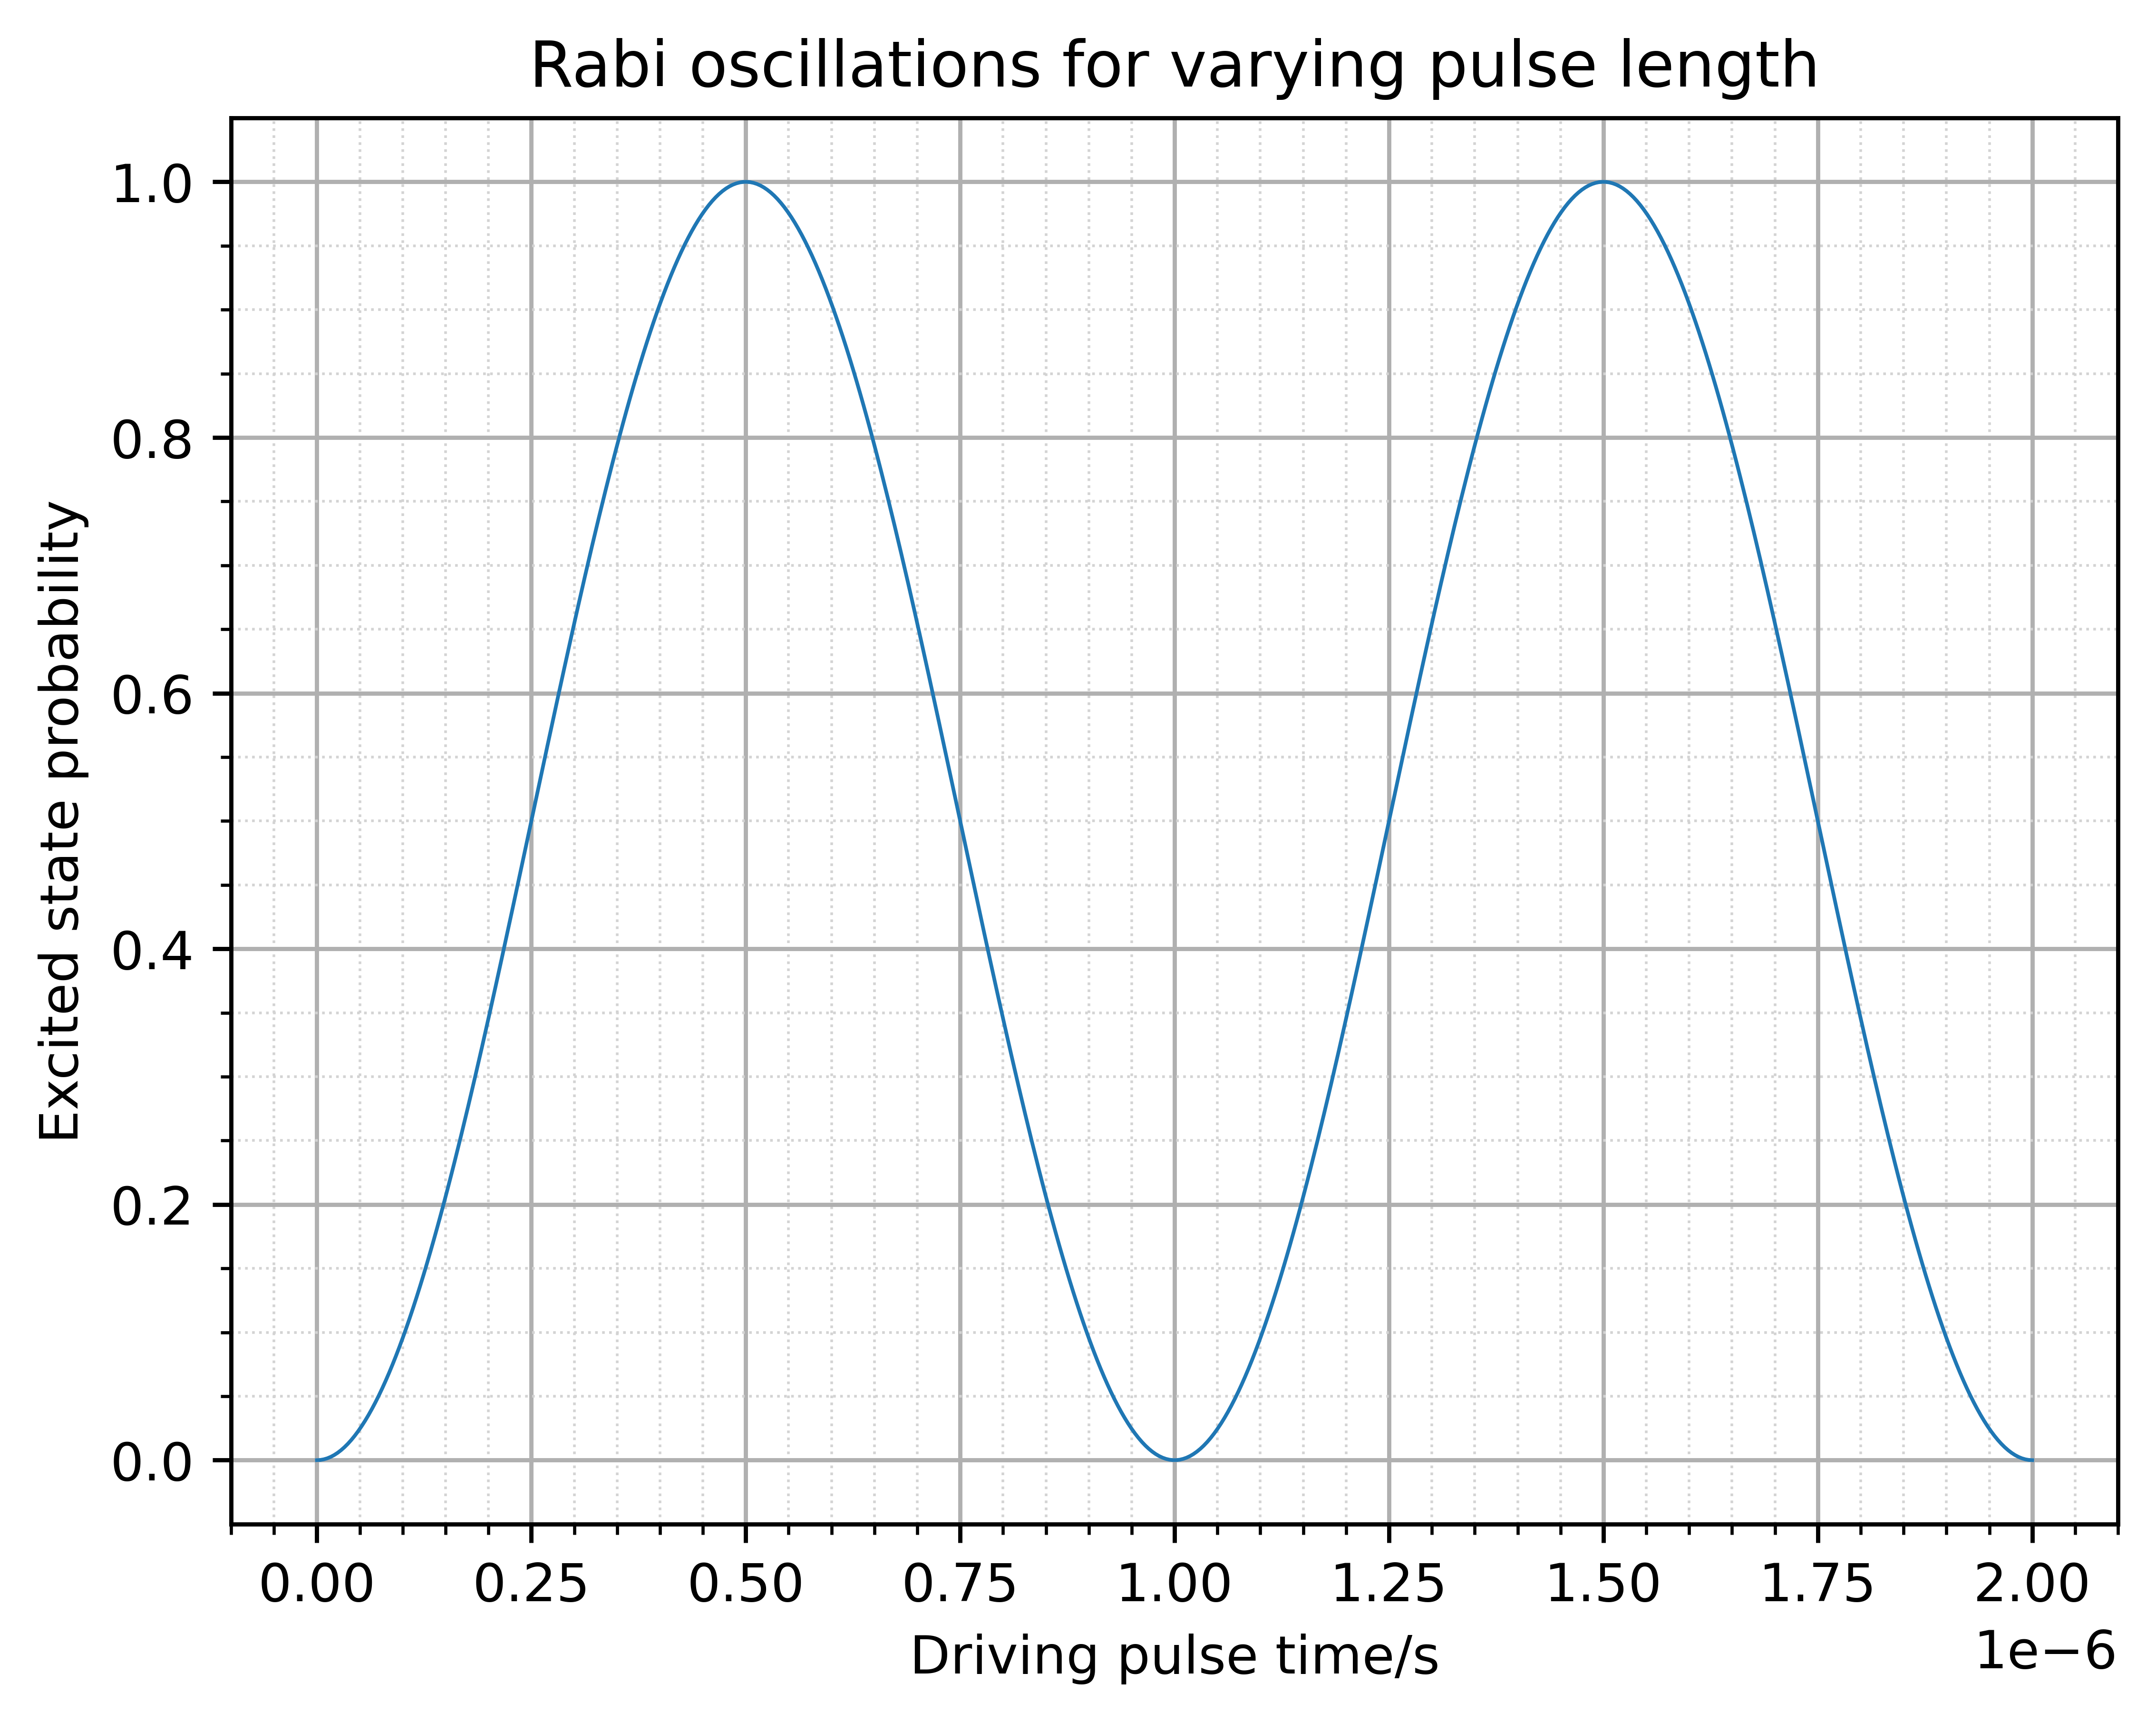

In [8]:
#Rabi oscillations
time = np.linspace(0,2e-6,500) #s
omega = 2*np.pi*1e6 #rad/s

H_drive = omega/2 *sx
P_excited = e1*e1.dag() #projection operator for excited state

output = mesolve(H_drive, g, time, c_ops=[], e_ops=[P_excited])

excited_prob = output.expect[0]

plt.figure(dpi=800)

plt.title('Rabi oscillations for varying pulse length')
plt.xlabel('Driving pulse time/s')
plt.ylabel('Excited state probability')
plt.plot(time, excited_prob, linewidth=0.7)
plt.grid(which='major',axis='both')
plt.grid(which='minor',axis='both',linestyle='dotted',linewidth=0.5,color='lightgrey')
plt.minorticks_on()

plt.show()

<>:38: SyntaxWarning: invalid escape sequence '\p'
<>:38: SyntaxWarning: invalid escape sequence '\p'
C:\Users\Admin\AppData\Local\Temp\ipykernel_8752\546526683.py:38: SyntaxWarning: invalid escape sequence '\p'
  f"Calculated T1 = {T1_fit*1e6:.2f} $\pm$ {T1_err*1e6:.2f} µs",


Calculated T1 = 49.9742 microseconds


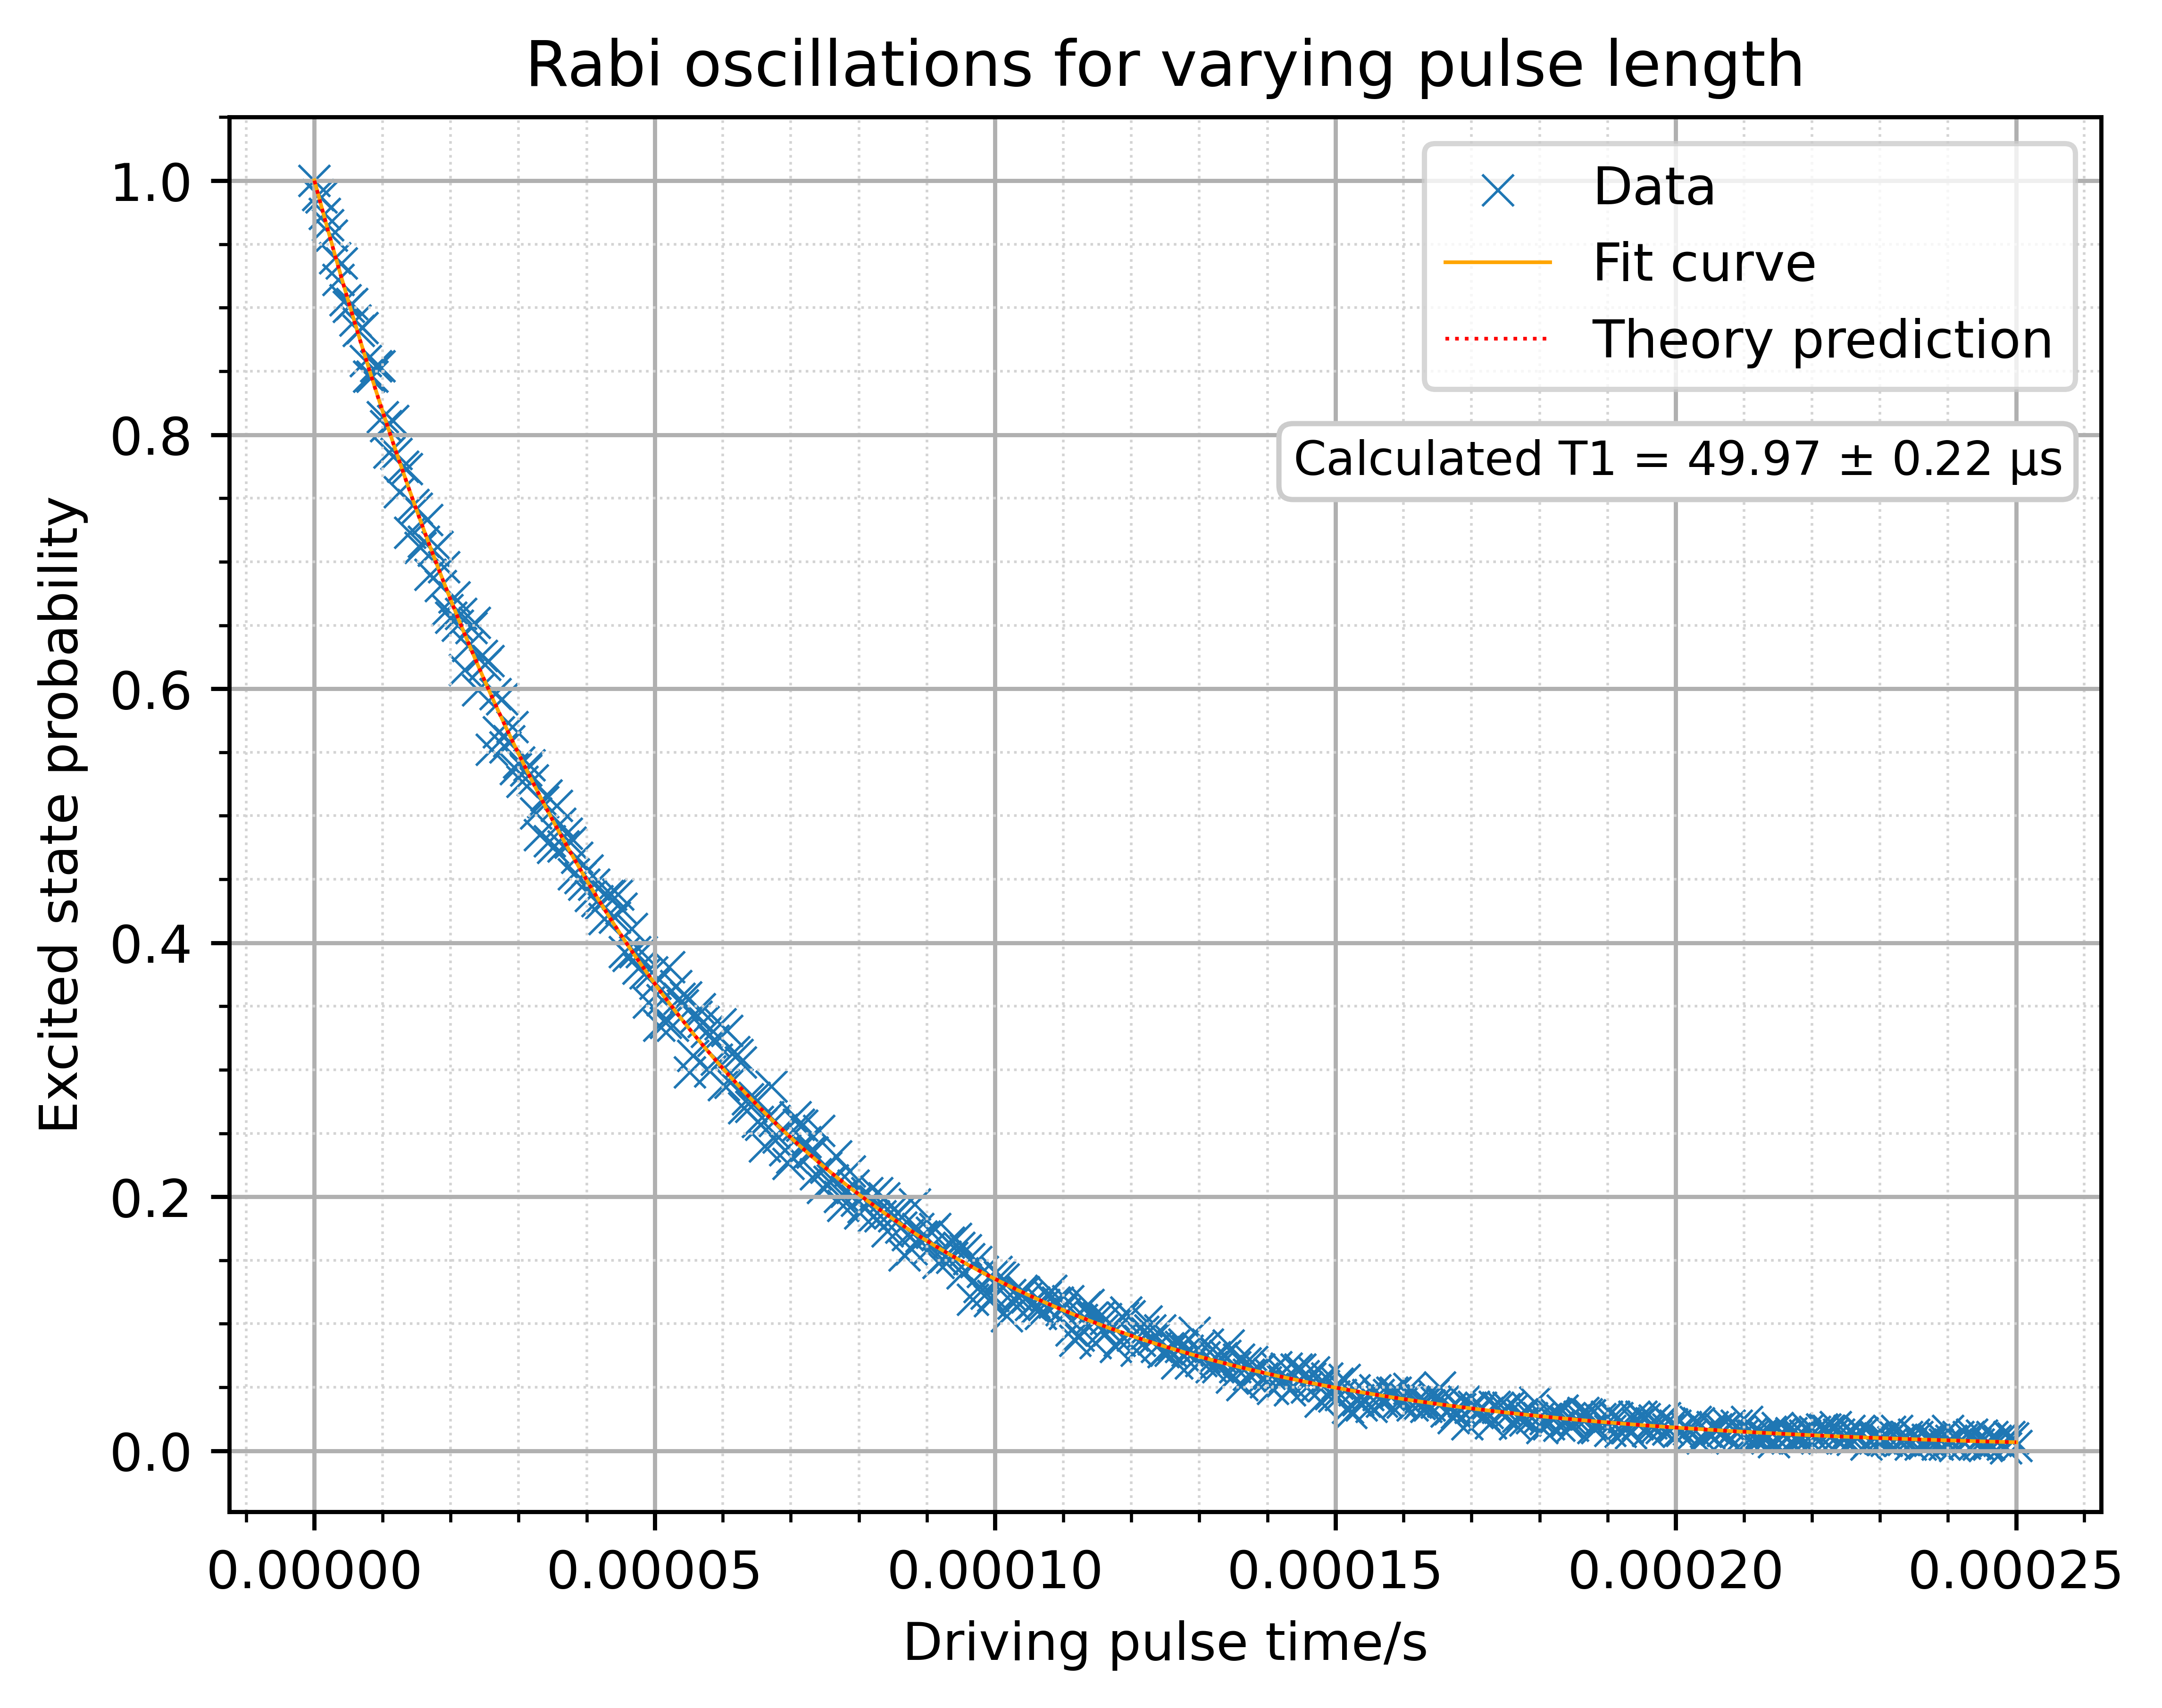

In [9]:
#T1 relaxation collapse
T1 = 50e-6 #s

time = np.linspace(0,250e-6,500) #s
omega = 2*np.pi*1e6 #rad/s

c1 = np.sqrt(1/T1)*g*e1.dag() # relaxation collapse operator
P_excited = e1*e1.dag() #projection operator for excited state

output = mesolve(H_q, e1, time, c_ops=[c1], e_ops=[P_excited])

excited_prob = output.expect[0]

shots = 1000
Prob = np.exp(-time/T1)
randomness = np.random.binomial(shots, Prob)/shots

def exponential(t, A, T1_fit, B):
    return A*np.exp(-t/T1_fit) + B

exp_fit, pcov = curve_fit(exponential, xdata=time, ydata=randomness, p0=[1,50e-6,0])
T1_fit = exp_fit[1]
perr = np.sqrt(np.diag(pcov))
T1_err = perr[1]
fitted = exponential(time, exp_fit[0], exp_fit[1], exp_fit[2])

print(f'Calculated T1 = {T1_fit*1e6:.4f} microseconds')

plt.figure(dpi=800)

plt.scatter(time, randomness , marker='x', linewidths=0.5, label='Data')
plt.plot(time, fitted, linewidth=0.7, color='orange', label='Fit curve')
plt.plot(time, excited_prob, linewidth=0.7, color='red', linestyle=':', label='Theory prediction')

plt.legend(loc='upper right')
plt.text(
    0.979, 0.77,
    f"Calculated T1 = {T1_fit*1e6:.2f} $\pm$ {T1_err*1e6:.2f} µs",
    transform=plt.gca().transAxes,
    fontsize=9,
    verticalalignment='top',
    horizontalalignment='right',
    bbox=dict(
        facecolor='white',
        edgecolor='0.8',
        boxstyle='round',
        alpha=1
    )
)

plt.title('Rabi oscillations for varying pulse length')
plt.xlabel('Driving pulse time/s')
plt.ylabel('Excited state probability')

plt.grid(which='major',axis='both')
plt.grid(which='minor',axis='both',linestyle='dotted',linewidth=0.5,color='lightgrey')
plt.minorticks_on()

plt.show()

<>:54: SyntaxWarning: invalid escape sequence '\p'
<>:54: SyntaxWarning: invalid escape sequence '\p'
C:\Users\Admin\AppData\Local\Temp\ipykernel_8752\2495273995.py:54: SyntaxWarning: invalid escape sequence '\p'
  f"Calculated T2 = {T2_fit:.2f} $ \pm $ {T2_err:.2f} µs",


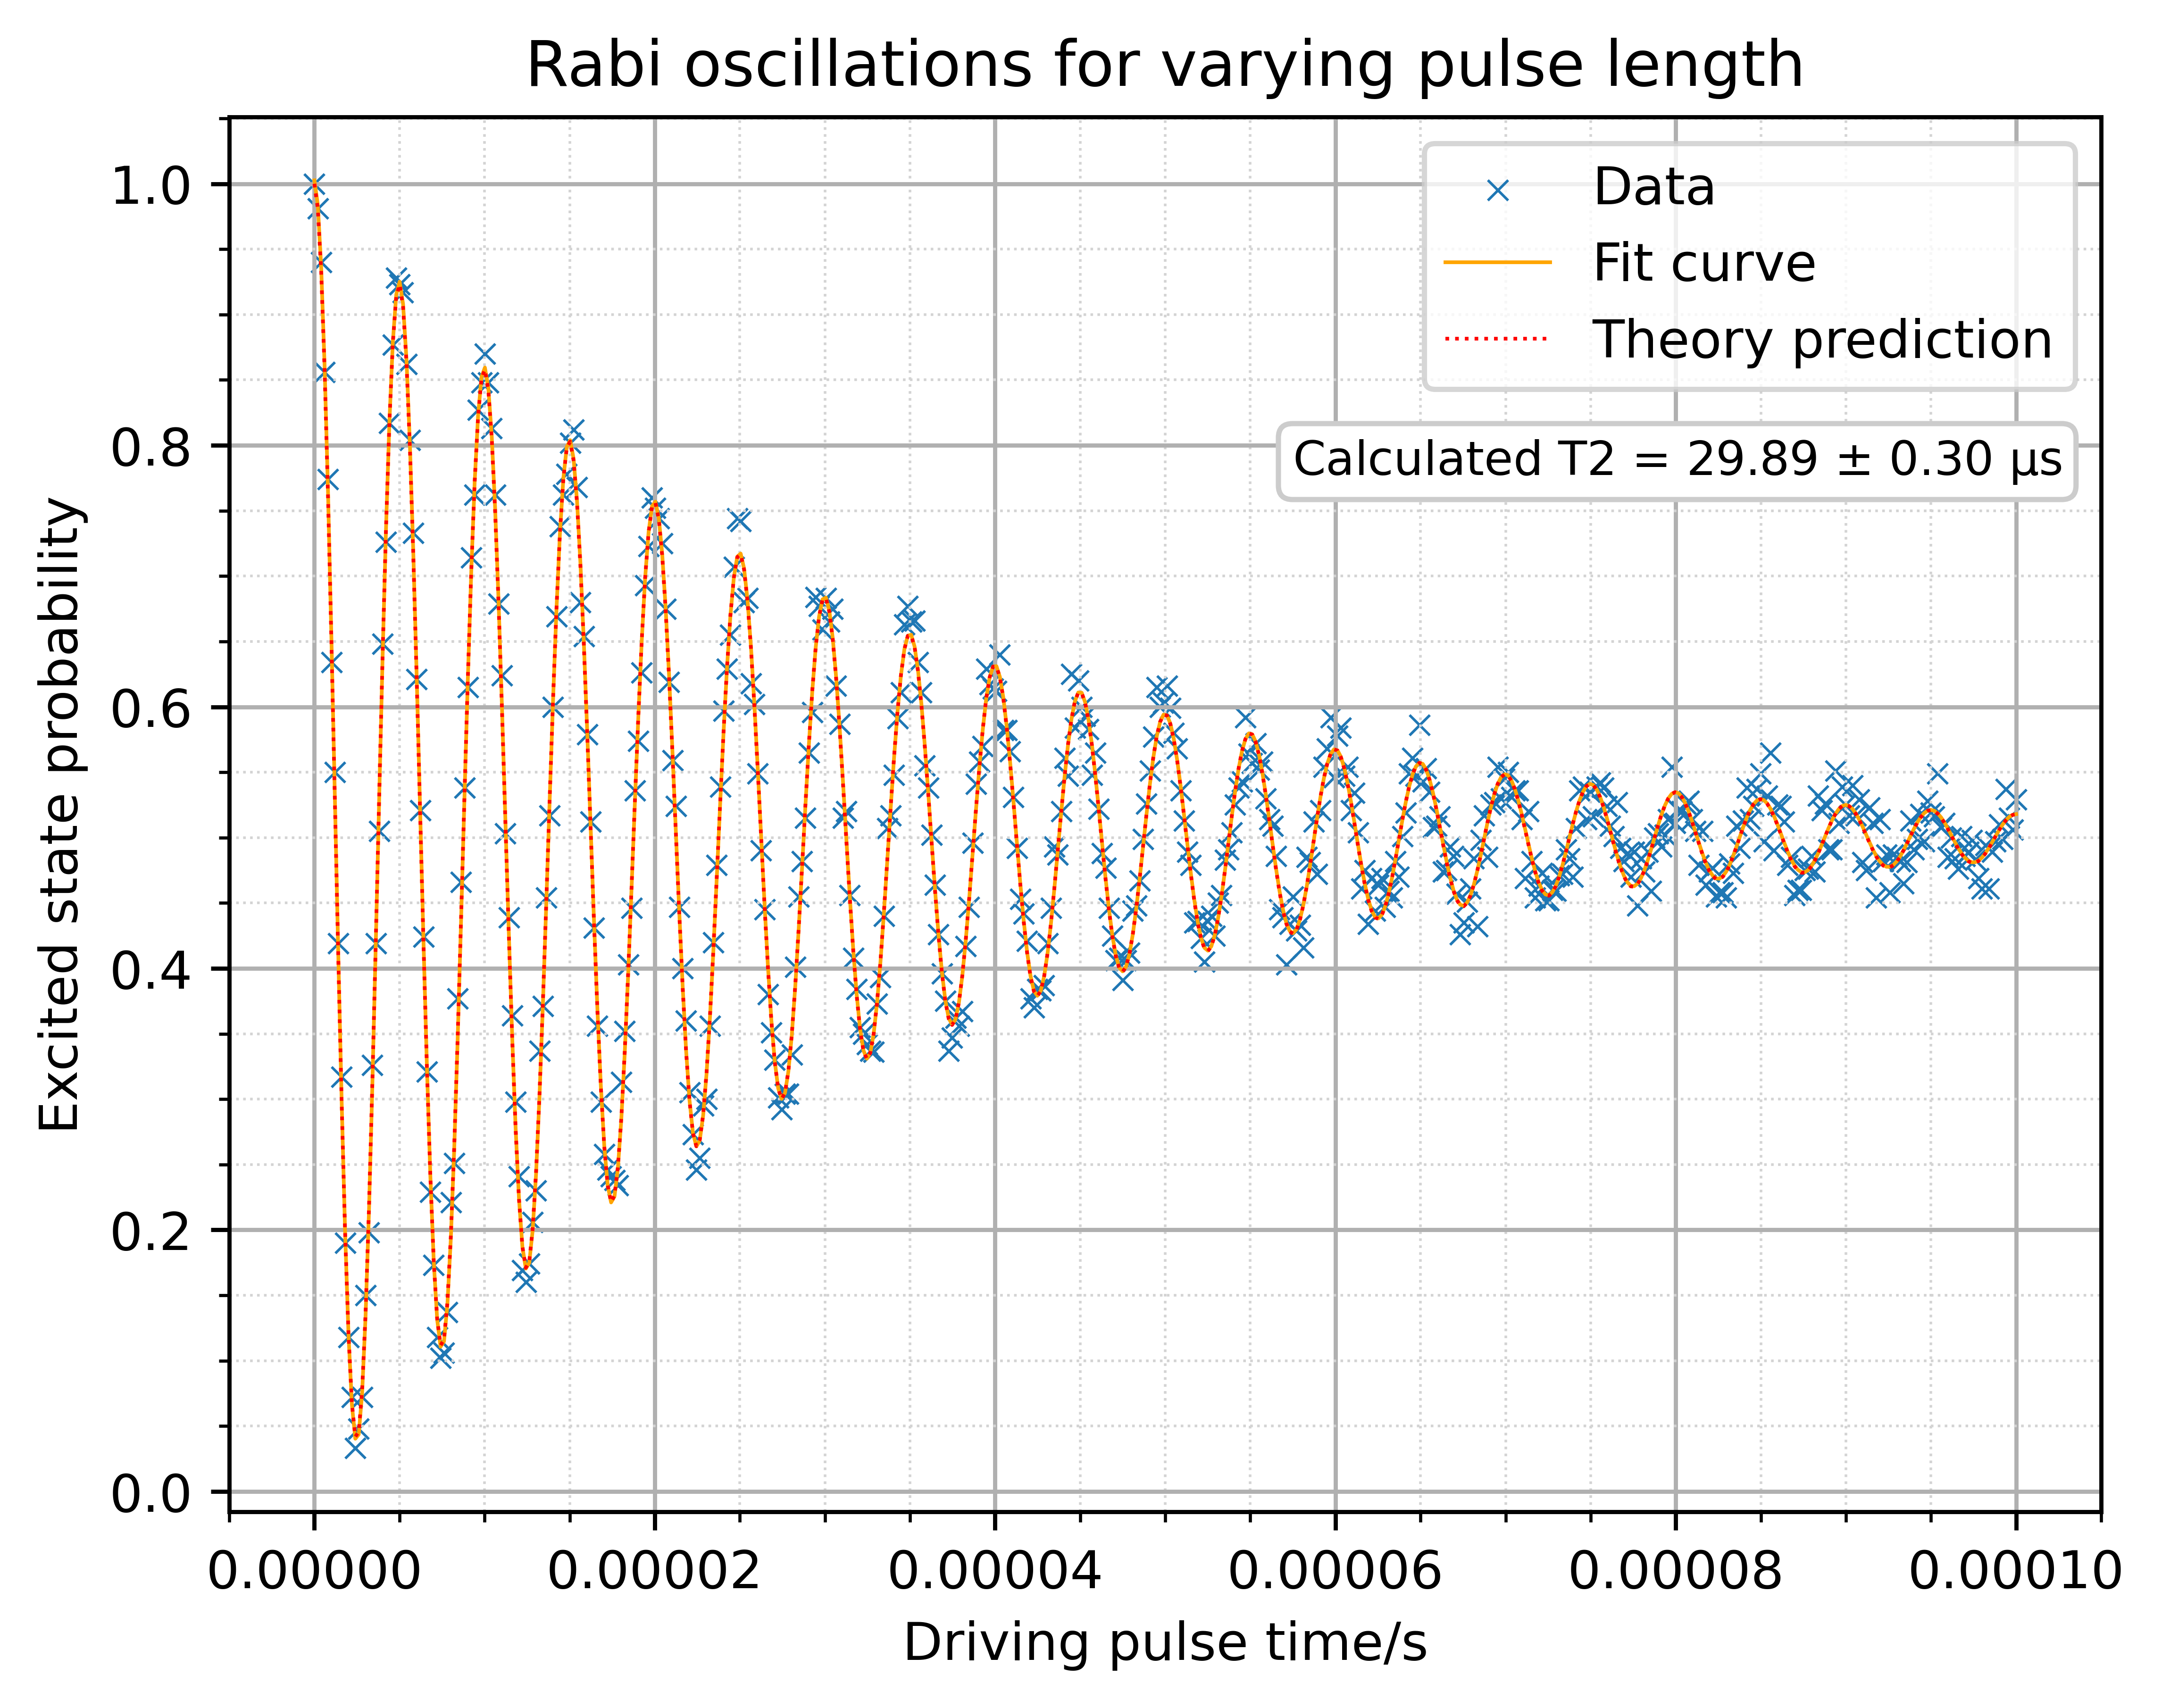

In [ ]:
#T2 relaxation collapse and Ramsey experiment
T2_star = 30*1e-6 #s
detuning = 0.2*1e6 #Hz, detuning frequency
delta_omega = 2*np.pi*detuning
T_phi = 1 / (1/T2_star - 1/(2*T1)) # Pure dephasing time


c1 = np.sqrt(1/T1)*g*e1.dag() # relaxation collapse operator
c2 = np.sqrt(1/(2*T_phi))*sz #pure dephasing
P_excited = e1*e1.dag() #projection operator for excited state
H_rot = delta_omega/2 * sz
excited_states = []
excited_prob = []

U_pi2 = (-1j * np.pi/4 * sx).expm() #pulse operator for pi/2
psi_init = U_pi2*g #initial state after pi/2 rotation
time = np.linspace(0,100e-6,500)
output = mesolve(H_rot, psi_init, time, c_ops=[c1,c2], e_ops=[])


for state in output.states:
    final_state = U_pi2*state*U_pi2.dag()
    
    probability=qt.expect(P_excited,final_state)
    excited_prob.append(np.real(probability))

excited_prob = np.array(excited_prob)

time_mus = time*1e6

shots = 1000
randomness = np.random.binomial(shots, excited_prob)/shots


def ramsey_fit(t,A,T2_fit, df,phi,B):
    return A*np.exp(-t/T2_fit)*np.cos(2*np.pi*df*t + phi) +B

ram_fit, pcov = curve_fit(ramsey_fit, xdata=time_mus, ydata=randomness, p0=[0.5, 30, 0.2, np.pi/2, 0.5], bounds=([0, 1, 0.01, -2*np.pi, 0], [1, 500, 1, 2*np.pi, 1]), maxfev=20000)
A_fit, T2_fit, df_fit, phi_fit, B_fit = ram_fit
ram_fitted = ramsey_fit(time_mus, A_fit, T2_fit, df_fit, phi_fit, B_fit)
perr = np.sqrt(np.diag(pcov))
T2_err = perr[1]


plt.figure(dpi=800)

plt.scatter(time, randomness, s=15, marker='x', linewidths=0.5, label='Data')
plt.plot(time, ram_fitted, linewidth=0.7, color='orange', label='Fit curve')
plt.plot(time, excited_prob, linewidth=0.7, color='red', linestyle=':', label='Theory prediction')

plt.legend(loc='upper right')
plt.text(
    0.979, 0.77,
    f"Calculated T2 = {T2_fit:.2f} $\pm$ {T2_err:.2f} µs",
    transform=plt.gca().transAxes,
    fontsize=9,
    verticalalignment='top',
    horizontalalignment='right',
    bbox=dict(
        facecolor='white',
        edgecolor='0.8',
        boxstyle='round',
        alpha=1
    )
)

plt.title('Rabi oscillations for varying pulse length')
plt.xlabel('Driving pulse time/s')
plt.ylabel('Excited state probability')

plt.grid(which='major',axis='both')
plt.grid(which='minor',axis='both',linestyle='dotted',linewidth=0.5,color='lightgrey')
plt.minorticks_on()

plt.show()